# HD 137010 b – what do the priors do?

With one transit the period is only constrained through the duration, so the priors matter. Here:
- the single-transit period prior (Kipping 2018) and the prior predictive transit duration,
- eccentricity priors and how they rescale the period,
- a quick rejection-ABC posterior for every prior combination,
- the full period posterior for each period prior (shape fit + reweighting), and which prior the authors used.

Model code in [`transit.py`](transit.py), samplers in [`run_shape.py`](run_shape.py) (emcee) and
[`run_dynesty.py`](run_dynesty.py) (nested sampling).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import transit as tr

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
rng = np.random.default_rng(1)
t, f, P_MIN = tr.load_data()
K = 0.0137                                   # Rp/R*, fixed by the depth

ALPHAS = {0.0: "kipping", -2 / 3: "uniform_a_kipping", -1.0: "loguniform_kipping"}
ALABEL = {0.0: r"$\alpha=0$ (unif. $P$)", -2 / 3: r"$\alpha=-2/3$ (unif. $a$)", -1.0: r"$\alpha=-1$ (log-unif. $P$)"}
E_LIST = ["circular", "rayleigh_vaneylen19", "beta_kipping13", "uniform"]

def wquantile(x, w, q):
    i = np.argsort(x)
    c = np.cumsum(w[i])
    return np.interp(q, c / c[-1], x[i])

def summ(x, w=None):
    w = np.ones_like(x) if w is None else w
    lo, med, hi = wquantile(x, w, [0.15865, 0.5, 0.84135])
    return f"{med:.0f} -{med - lo:.0f} +{hi - med:.0f}"

# observed duration, from the e = 0, alpha = 0 nested-sampling posterior
post_ref = np.load("results/dynesty_kipping.npz")["samples"]
d_ref = tr.derived(post_ref)
T14_OBS, T14_SIG = np.median(d_ref["T14_hr"]), np.std(d_ref["T14_hr"])
print(f"T14 = {T14_OBS:.2f} ± {T14_SIG:.2f} h, P_min = {P_MIN:.1f} d")

/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/.venv/lib/python3.13/site-packages/batman/tests.py:107: SyntaxWarning: invalid escape sequence '\ '
  )   \     /   (
/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/.venv/lib/python3.13/site-packages/batman/tests.py:119: SyntaxWarning: invalid escape sequence '\/'
  /_ \/ |__


T14 = 9.77 ± 0.20 h, P_min = 64.2 d


## 1. Single-transit period prior

For an intrinsic period distribution $p(P)\propto P^{\alpha}$ and a planet seen to transit exactly once
(Kipping 2018):
$$
p(P\mid\text{single transit}) \propto P^{\alpha}\cdot\underbrace{P^{-2/3}}_{\text{transit prob.}}\cdot\underbrace{P^{-1}}_{\text{window}} = P^{\alpha-5/3}.
$$
$\alpha$ describes the planet population; the data say nothing about it. We use $\alpha=0$ (uniform in $P$),
$-2/3$ (uniform in $a$) and $-1$ (log-uniform in $P$).

$\alpha=0$ (unif. $P$)         prior Pr(P > 300 d) = 0.286
$\alpha=-2/3$ (unif. $a$)      prior Pr(P > 300 d) = 0.119
$\alpha=-1$ (log-unif. $P$)    prior Pr(P > 300 d) = 0.074


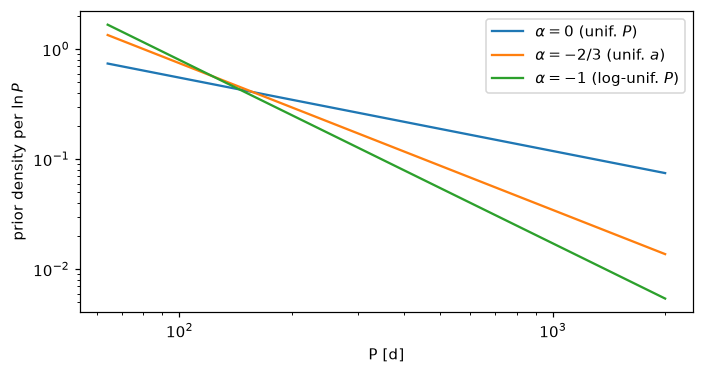

In [2]:
def sample_P(alpha, n, p_max=tr.P_MAX):
    # inverse CDF of p(P) ~ P^(alpha - 5/3) on [P_MIN, p_max]
    s = alpha - 5 / 3 + 1
    lo, hi = P_MIN**s, p_max**s
    return (lo + rng.uniform(size=n) * (hi - lo)) ** (1 / s)

P_grid = np.geomspace(P_MIN, tr.P_MAX, 500)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for a in ALPHAS:
    dens = P_grid ** (a - 5 / 3 + 1)            # density per ln P
    ax.plot(P_grid, dens / np.trapezoid(dens, np.log(P_grid)), label=ALABEL[a])
    print(f"{ALABEL[a]:30s} prior Pr(P > 300 d) = {np.mean(sample_P(a, 10**6) > 300):.3f}")
ax.set(xscale="log", yscale="log", xlabel="P [d]", ylabel=r"prior density per $\ln P$")
ax.legend()
fig.tight_layout()

All three put little weight near 1 yr, so a posterior near 300 d comes from the data. The prior mostly sets
the long-period tail.

## 2. Prior predictive transit duration

Draw $P$, $\log\rho_*\sim\mathcal N(0.462, 0.041)$, $b\sim U(0,1+k)$ (and $e,\omega$ in Sec. 3) and compute
$$
T_{14} = \frac{P}{\pi}\arcsin\!\left(\frac{\sqrt{(1+k)^2-b^2}}{a/R_*}\right)\frac{\sqrt{1-e^2}}{1+e\sin\omega}.
$$
Eccentric draws are weighted by the transit probability $(1+e\sin\omega)/(1-e^2)$; orbits with periastron
$a(1-e) < 2R_*$ are removed.

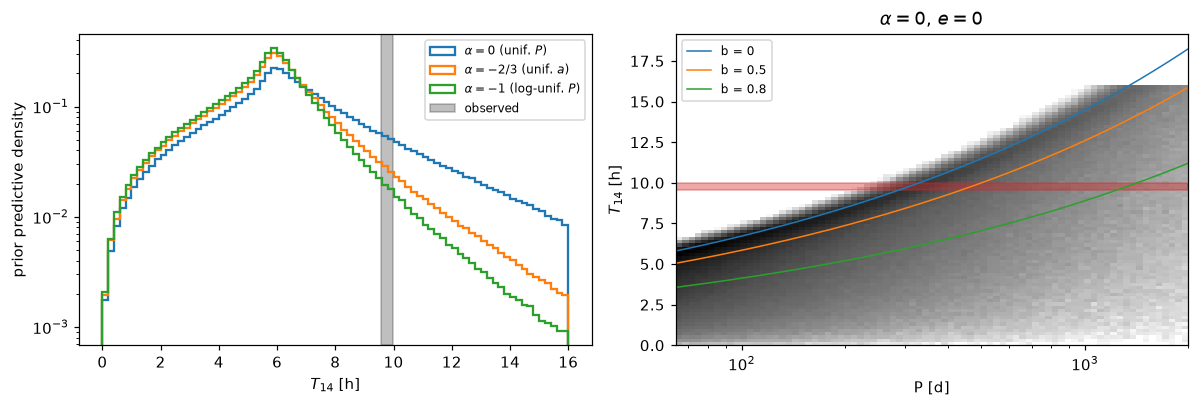

In [3]:
def prior_predictive(alpha, e_prior="circular", n=2_000_000, p_max=tr.P_MAX):
    P = sample_P(alpha, n, p_max)
    log_rho = rng.normal(*tr.LOG_RHO_PRIOR, n)
    b = rng.uniform(0, 1 + K, n)
    e, w = tr.draw_e_w(e_prior, n, rng)
    aR = tr.a_over_rstar(P, log_rho)
    ok = (e < 1) & (aR * (1 - np.minimum(e, 1)) > 2)
    e = np.where(ok, e, 0.0)
    g = tr.g_factor(e, w)
    wt = np.where(ok, tr.transit_prob_factor(e, w), 0.0)
    T14 = P / np.pi * np.arcsin(np.clip(np.sqrt((1 + K) ** 2 - b**2) / aR, 0, 1)) / g * 24
    return pd.DataFrame(dict(P=P, e=e, g=g, T14=T14, wt=wt / wt.sum()))

pp0 = prior_predictive(0.0)
fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 3.8))
for a in ALPHAS:
    pp = pp0 if a == 0 else prior_predictive(a)
    a0.hist(pp.T14, bins=np.linspace(0, 16, 81), weights=pp.wt, histtype="step", lw=1.5, density=True, label=ALABEL[a])
a0.axvspan(T14_OBS - T14_SIG, T14_OBS + T14_SIG, color="k", alpha=0.25, label="observed")
a0.set(xlabel=r"$T_{14}$ [h]", ylabel="prior predictive density", yscale="log")
a0.legend(fontsize=8)

a1.hist2d(pp0.P, pp0.T14, bins=[np.geomspace(P_MIN, 2000, 80), np.linspace(0, 16, 80)], cmap="Greys", norm="log")
a1.axhspan(T14_OBS - T14_SIG, T14_OBS + T14_SIG, color="C3", alpha=0.4)
for bb in [0, 0.5, 0.8]:
    T_b = P_grid / np.pi * np.sqrt((1 + K) ** 2 - bb**2) / tr.a_over_rstar(P_grid, tr.LOG_RHO_PRIOR[0]) * 24
    a1.plot(P_grid, T_b, lw=1, label=f"b = {bb}")
a1.set(xscale="log", xlabel="P [d]", ylabel=r"$T_{14}$ [h]", title=r"$\alpha=0$, $e=0$")
a1.legend(fontsize=8, loc="upper left")
fig.tight_layout()

Most prior draws give $T_{14}\approx 6$ h; the observed 9.8 h is in the upper tail. For $e=0$ the $b=0$ curve
sets a lower limit $P\gtrsim250$ d, and larger $b$ needs longer $P$.

## 3. Eccentricity priors

| name | $p(e)$ | motivation |
|---|---|---|
| `circular` | $e=0$ | paper |
| `rayleigh_vaneylen19` | Rayleigh($\sigma=0.049$) | small planets in multis (Van Eylen et al. 2019) |
| `beta_kipping13` | Beta(0.867, 3.03) | RV planets (Kipping 2013) |
| `uniform` | $U(0,1)$ | no information |

Two effects:
- transit probability $\propto (1+e\sin\omega)/(1-e^2)$: eccentric orbits near periastron are favoured,
- at fixed $\rho_*$, $T_{14}\propto P^{1/3}/g$ with $g=(1+e\sin\omega)/\sqrt{1-e^2}$, so $P = P_{\rm circ}\,g^3$
  (Dawson & Johnson 2012).

/var/folders/tc/mprgbpgd4q91wy89m869r5c80000gn/T/ipykernel_77373/3056929191.py:7: RuntimeWarning: invalid value encountered in divide
  axes[0].plot(egrid, pe_tr / np.trapezoid(pe_tr, egrid), color=f"C{j+1}", ls="--")


rayleigh_vaneylen19  90% range of P/P_circ = g^3: [0.79, 1.29]
beta_kipping13       90% range of P/P_circ = g^3: [0.45, 7.45]


uniform              90% range of P/P_circ = g^3: [0.41, 1254.98]


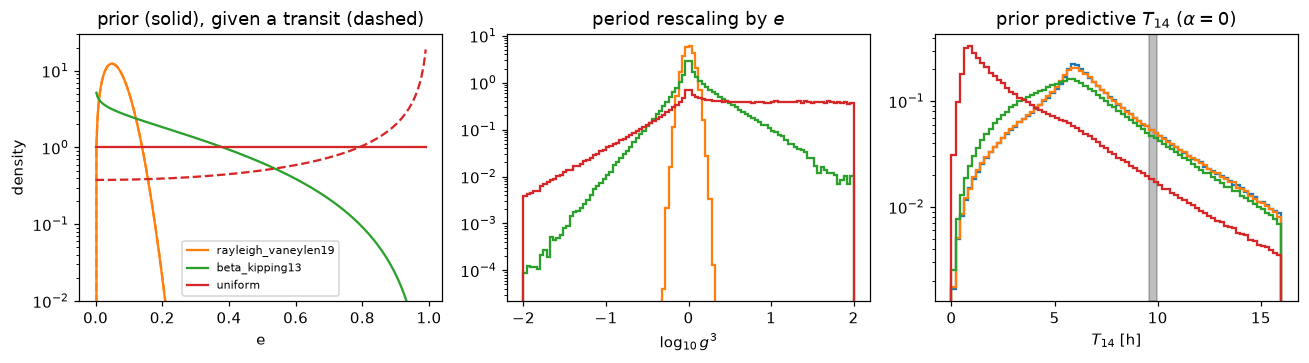

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
egrid = np.linspace(0, 0.99, 400)
for j, name in enumerate(E_LIST[1:]):
    pe = tr.E_PRIORS[name].pdf(egrid)
    pe_tr = pe / (1 - egrid**2)                  # averaged over w: (1 + e sin w)/(1 - e^2) -> 1/(1 - e^2)
    axes[0].plot(egrid, pe, color=f"C{j+1}", label=name)
    axes[0].plot(egrid, pe_tr / np.trapezoid(pe_tr, egrid), color=f"C{j+1}", ls="--")
axes[0].set(xlabel="e", ylabel="density", yscale="log", ylim=(1e-2, 30), title="prior (solid), given a transit (dashed)")
axes[0].legend(fontsize=7)

for j, name in enumerate(E_LIST[1:]):
    pp = prior_predictive(0.0, name, n=500_000)
    axes[1].hist(np.log10(pp.g**3), bins=np.linspace(-2, 2, 101), weights=pp.wt, density=True,
                 histtype="step", lw=1.5, color=f"C{j+1}")
    lo, hi = wquantile(pp.g.values**3, pp.wt.values, [0.05, 0.95])
    print(f"{name:20s} 90% range of P/P_circ = g^3: [{lo:.2f}, {hi:.2f}]")
axes[1].set(xlabel=r"$\log_{10} g^3$", yscale="log", title="period rescaling by $e$")

for j, name in enumerate(E_LIST):
    pp = prior_predictive(0.0, name, n=1_000_000)
    axes[2].hist(pp.T14, bins=np.linspace(0, 16, 81), weights=pp.wt, density=True, histtype="step",
                 lw=1.5, color=f"C{j}", label=name)
axes[2].axvspan(T14_OBS - T14_SIG, T14_OBS + T14_SIG, color="k", alpha=0.25)
axes[2].set(xlabel=r"$T_{14}$ [h]", yscale="log", title=r"prior predictive $T_{14}$ ($\alpha=0$)")
fig.tight_layout()

## 4. Rejection ABC on $T_{14}$

Keep the prior-predictive draws with $|T_{14}-T_{14}^{\rm obs}|<\sigma_{T_{14}}$ (weighted by the transit
probability). The kept draws approximate $p(P\mid T_{14}^{\rm obs})$, and the acceptance rate estimates
$p(T_{14}^{\rm obs}\mid\mathcal M)$, so ratios are rough Bayes factors. Approximate: $T_{14}$ is not sufficient
and the ingress shape (information on $b$) is ignored.

,alpha,e prior,ABC P [d],Pr(P<200 d),Pr(P>500 d),p(T14_obs | M) [rel.]
0,0.00,circular,374 -68 +268,0.000,0.262,1.000
1,0.00,rayleigh_vaneylen19,383 -92 +266,0.003,0.272,1.002
2,0.00,beta_kipping13,378 -168 +398,0.144,0.329,0.885
3,0.00,uniform,349 -219 +561,0.278,0.346,0.335
4,-0.67,circular,353 -54 +164,0.000,0.174,0.530
5,-0.67,rayleigh_vaneylen19,354 -76 +173,0.004,0.183,0.529
6,-0.67,beta_kipping13,303 -163 +232,0.272,0.183,0.530
7,-0.67,uniform,203 -114 +303,0.494,0.162,0.245
8,-1.00,circular,346 -51 +140,0.000,0.146,0.365
9,-1.00,rayleigh_vaneylen19,345 -71 +143,0.005,0.148,0.371


full posterior (dynesty, alpha=0, e=0): P = 384 -79 +323


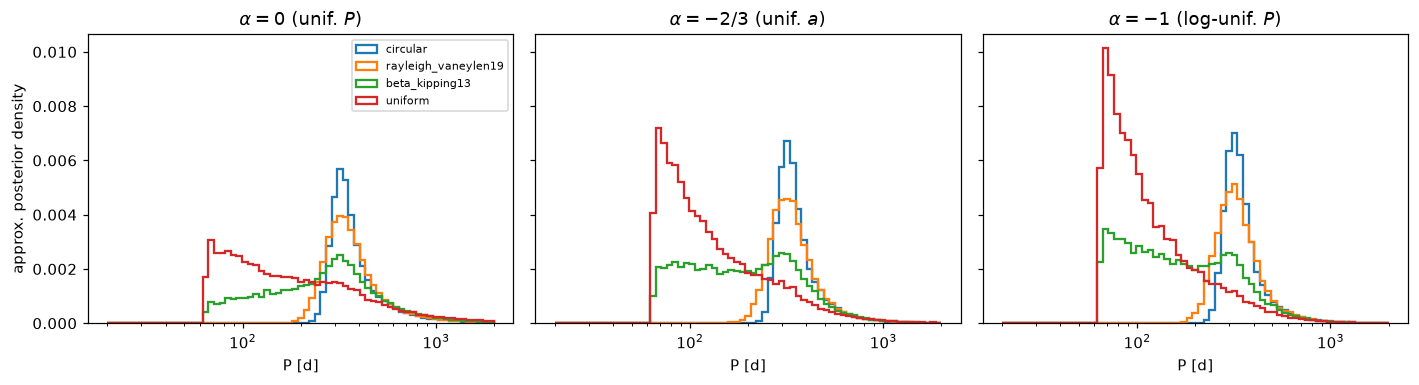

In [5]:
rows, abc = [], {}
for a in ALPHAS:
    for name in E_LIST:
        pp = prior_predictive(a, name)
        acc = (np.abs(pp.T14 - T14_OBS) < T14_SIG).values
        P, w = pp.P.values[acc], pp.wt.values[acc]
        abc[a, name] = (P, w)
        rows.append({"alpha": f"{a:.2f}", "e prior": name, "ABC P [d]": summ(P, w),
                     "Pr(P<200 d)": w[P < 200].sum() / w.sum(), "Pr(P>500 d)": w[P > 500].sum() / w.sum(),
                     "p(T14_obs | M) [rel.]": w.sum()})
tab = pd.DataFrame(rows)
tab["p(T14_obs | M) [rel.]"] /= tab["p(T14_obs | M) [rel.]"].iloc[0]
display(tab.round(3))
print("full posterior (dynesty, alpha=0, e=0): P =", summ(d_ref["P"]))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, a in zip(axes, ALPHAS):
    for j, name in enumerate(E_LIST):
        P, w = abc[a, name]
        ax.hist(P, bins=np.geomspace(20, 2000, 70), weights=w, density=True, histtype="step", lw=1.5,
                color=f"C{j}", label=name)
    ax.set(xscale="log", xlabel="P [d]", title=ALABEL[a])
axes[0].set_ylabel("approx. posterior density")
axes[0].legend(fontsize=7)
fig.tight_layout()

## 5. Period posterior for each period prior ($e=0$)

For $a/R_*\gg1$ the planet crosses the star on a straight line, so the light curve depends on the orbit only
through $b$ and $v=(a/R_*)/P\cdot g(e,\omega)$. We fit this "shape" once ([`run_shape.py`](run_shape.py), flat in
$\ln v$) and get the physical parameters from
$$
P = \frac{G\rho_*\,g^3}{3\pi v^3},
$$
drawing $\rho_*$ (and $e,\omega$ in 04) from their priors. $\partial\ln P/\partial\ln v=-3$ is constant, so any
prior on $(P,\rho_*,e,\omega)$ is just an importance weight $w\propto p(\ln P)\,p_{\rm tr}(e,\omega)$
([`transit.shape_to_physical`](transit.py)). One fit thus serves all priors.

Check against nested sampling of the full model in $(P, b, \rho_*, \dots)$ ([`run_dynesty.py`](run_dynesty.py)):

In [6]:
shape = np.load("results/shape.npz")
sh = shape["chain"][shape["chain"].shape[0] // 2:]
shape_post = sh.reshape(-1, sh.shape[-1])
print(f"shape chain: {shape['chain'].shape[0] * int(shape['thin'])} steps, "
      f"tau_max = {shape['tau_history'][-1, 1:].max():.0f} steps")

def weighted(prior, p_max=tr.P_MAX):
    th, _, _, w = tr.shape_to_physical(shape_post, prior, p_min=P_MIN, p_max=p_max, n_draws=5, rng=0)
    return th, w

rows = []
for name in ["kipping", "loguniform_kipping"]:
    dy = np.load(f"results/dynesty_{name}.npz")["samples"]
    th, w = weighted(name)
    for lab, s, ww in [("shape + reweighting", th, w), ("dynesty", dy, np.full(len(dy), 1 / len(dy)))]:
        P = np.exp(s[:, 1])
        rows.append({"prior": name, "method": lab, "P [d]": summ(P, ww), "Pr(P>1000 d)": ww[P > 1000].sum(),
                     "b (3σ upper)": wquantile(s[:, 2], ww, 0.9973)})
display(pd.DataFrame(rows).set_index(["prior", "method"]).round(3))

shape chain: 130000 steps, tau_max = 945 steps


P [d]  Pr(P>1000 d)  \
prior              method                                            
kipping            shape + reweighting  385 -80 +328         0.080   
                   dynesty              384 -79 +323         0.083   
loguniform_kipping shape + reweighting  349 -56 +158         0.025   
                   dynesty              347 -54 +150         0.031   

                                        b (3σ upper)  
prior              method                             
kipping            shape + reweighting         0.849  
                   dynesty                     0.850  
loguniform_kipping shape + reweighting         0.830  
                   dynesty                     0.833

P [d]  mode [d]  Pr(P>1000 d)  \
prior                       P_max                                         
$\alpha=0$ (unif. $P$)      2000   385 -80 +328   329.946         0.080   
                            10000  391 -85 +398   329.946         0.109   
$\alpha=-2/3$ (unif. $a$)   2000   358 -61 +196   320.970         0.037   
                            10000  359 -62 +207   320.970         0.046   
$\alpha=-1$ (log-unif. $P$) 2000   349 -56 +158   320.970         0.025   
                            10000  349 -56 +162   320.970         0.030   

                                  I [I_earth]  ESS / N  
prior                       P_max                       
$\alpha=0$ (unif. $P$)      2000   26-15+11 %    0.819  
                            10000  26-16+11 %    0.865  
$\alpha=-2/3$ (unif. $a$)   2000    29-13+9 %    0.692  
                            10000   29-13+9 %    0.704  
$\alpha=-1$ (log-unif. $P$) 2000    30-12+9 %    0.635  
                            10000   30-12+9 %    0.641

Bayes factor alpha=0 vs -1: dynesty 2.2 (ln B = 0.80 ± 0.22), ABC 2.7


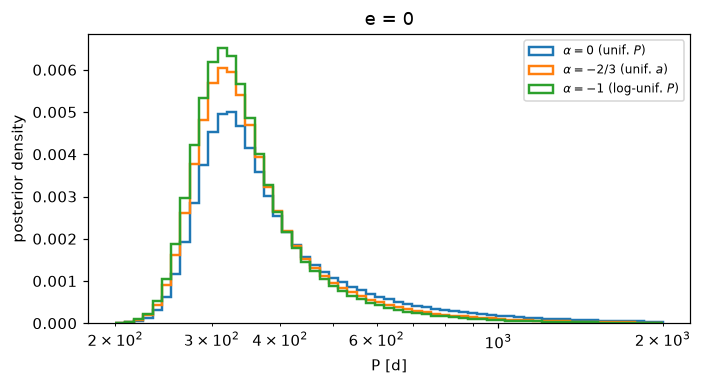

In [7]:
def mode_P(P, w):
    h, e = np.histogram(np.log(P), bins=150, weights=w)
    return np.exp(0.5 * (e[h.argmax()] + e[h.argmax() + 1]))

rows, curves = [], {}
for a, name in ALPHAS.items():
    for p_max in [tr.P_MAX, 1e4]:
        th, w = weighted(name, p_max)
        P = np.exp(th[:, 1])
        I = tr.derived(th, rng=2)["insolation"]
        rows.append({"prior": ALABEL[a], "P_max": int(p_max), "P [d]": summ(P, w), "mode [d]": mode_P(P, w),
                     "Pr(P>1000 d)": w[P > 1000].sum(), "I [I_earth]": summ(I * 100, w).replace(" ", "") + " %",
                     "ESS / N": 1 / np.sum(w**2) / len(w)})
        if p_max == tr.P_MAX:
            curves[a] = (P, w)
display(pd.DataFrame(rows).set_index(["prior", "P_max"]).round(3))

lnZ = {n: float(np.load(f"results/dynesty_{n}.npz")["logz"]) for n in ["kipping", "loguniform_kipping"]}
err = np.hypot(*[float(np.load(f"results/dynesty_{n}.npz")["logzerr"]) for n in lnZ])
lnB = lnZ["kipping"] - lnZ["loguniform_kipping"]
abc_ratio = tab.loc[0, "p(T14_obs | M) [rel.]"] / tab.loc[8, "p(T14_obs | M) [rel.]"]
print(f"Bayes factor alpha=0 vs -1: dynesty {np.exp(lnB):.1f} (ln B = {lnB:.2f} ± {err:.2f}), ABC {abc_ratio:.1f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for a, (P, w) in curves.items():
    ax.hist(P, bins=np.geomspace(200, 2000, 60), weights=w, density=True, histtype="step", lw=1.6, label=ALABEL[a])
ax.set(xscale="log", xlabel="P [d]", ylabel="posterior density", title="e = 0")
ax.legend(fontsize=8)
fig.tight_layout()

## 6. Which period prior did the authors use?

The authors sent their posterior samples ([`posteriors.csv`](posteriors.csv), every 10th sample). We reweight
our shape posterior to a range of $\alpha$, without upper cut (their chain has samples above 2000 d), and
compare the period distribution with theirs (KS distance).

,KS distance,P [d],Pr(P>1000),Pr(P>2000),b (3σ)
alpha,,,,,
0.0,0.1343,391 -85 +398,0.1088,0.0318,0.9256
-0.1,0.1147,384 -80 +355,0.0957,0.0263,0.9211
-0.2,0.0961,378 -76 +318,0.0842,0.0218,0.9156
-0.3,0.0783,373 -72 +287,0.0740,0.0181,0.9106
-0.4,0.0613,369 -69 +261,0.0650,0.0149,0.9052
-0.5,0.0450,364 -66 +238,0.0570,0.0123,0.8998
-0.6,0.0294,361 -64 +218,0.0500,0.0101,0.8937
-0.7,0.0144,358 -61 +201,0.0439,0.0084,0.8871
-0.8,0.0085,355 -60 +187,0.0385,0.0069,0.8804


authors: P = 355 -59 +190  Pr(P>1000) = 0.0323  Pr(P>2000) = 0.0017  b (3σ) = 0.843


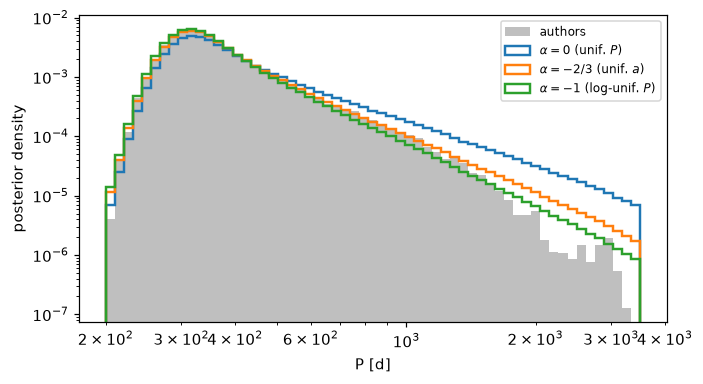

In [8]:
authors = pd.read_csv("posteriors.csv", index_col=0)
th_all, w_all = weighted("kipping", p_max=1e5)       # alpha = 0, no upper cut
P_all = np.exp(th_all[:, 1])
order = np.argsort(P_all)
grid = np.sort(authors.P.values)
ecdf = np.arange(1, len(grid) + 1) / len(grid)

rows = []
for a in np.round(np.arange(0.0, -1.41, -0.1), 2):
    w = w_all * P_all**a                              # alpha = 0 -> alpha = a
    w /= w.sum()
    ks = np.max(np.abs(np.interp(grid, P_all[order], np.cumsum(w[order])) - ecdf))
    rows.append({"alpha": a, "KS distance": ks, "P [d]": summ(P_all, w), "Pr(P>1000)": w[P_all > 1000].sum(),
                 "Pr(P>2000)": w[P_all > 2000].sum(), "b (3σ)": wquantile(th_all[:, 2], w, 0.9973)})
display(pd.DataFrame(rows).set_index("alpha").round(4))
print("authors: P =", summ(authors.P.values), f" Pr(P>1000) = {np.mean(authors.P > 1000):.4f}",
      f" Pr(P>2000) = {np.mean(authors.P > 2000):.4f}", f" b (3σ) = {np.percentile(authors.b, 99.73):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bins = np.geomspace(200, 3500, 60)
ax.hist(authors.P, bins=bins, density=True, color="k", alpha=0.25, label="authors")
for a in ALPHAS:
    ax.hist(P_all, bins=bins, weights=w_all * P_all**a, density=True, histtype="step", lw=1.6, label=ALABEL[a])
ax.set(xscale="log", yscale="log", xlabel="P [d]", ylabel="posterior density")
ax.legend(fontsize=8)
fig.tight_layout()

## Conclusions

- All period priors put only 7–29 % of the prior mass above 300 d. The ≈ 1 yr solution comes from the long
  duration; the prior mostly sets the long-period tail.
- Prior draws typically give $T_{14}\approx6$ h. The observed 9.8 h needs $P\gtrsim250$ d for $e=0$.
- Eccentricity rescales the period by $g^3$: 90 % range [0.79, 1.29] for Rayleigh 0.049, [0.45, 7.5] for Beta,
  [0.41, >1000] for uniform. ABC: with Beta or uniform $e$, 14–60 % of the posterior lies at $P<200$ d; the
  Rayleigh prior gives almost the circular result. The HZ question depends on the $e$ prior (→ 04).
- ABC evidences: circular and Rayleigh predict the duration best, uniform $e$ 3–5× worse. Small factors – one
  transit can't really choose between the priors.
- $e=0$ posterior: $P = 385^{+328}_{-80}$ d ($\alpha=0$), $358^{+196}_{-61}$ d ($\alpha=-2/3$), $349^{+158}_{-56}$ d
  ($\alpha=-1$); mode ≈ 320–330 d. Shape fit + reweighting agrees with nested sampling. Bayes factor
  $\alpha=0$ vs $-1$: 2.2 (ABC: 2.7), i.e. not decisive.
- Incident flux at $e=0$: 26–30 % $I_\oplus$ for every period prior.
- $P_{\max}$: going from 2000 to $10^4$ d lengthens the $\alpha=0$ tail (+328 → +398 d, $\Pr(P>1000)$ 8 → 11 %),
  small effect for $\alpha\le-2/3$.
- Authors' samples: best match at $\alpha\approx-0.8$; $\alpha=-1$ (log-uniform × Kipping, as written in the
  paper) gives KS 0.03, the same small difference as in 02b. 0.17 % of their samples lie above 2000 d, so
  the 2000 d cut is not applied as a hard cut in this chain.